# Pileup-Corrected $T(\mu)$ vs. Pileup-Corrected $T(\mu)$

Single-region Quadrant Analysis and Feature Distribution comparison.

In [4]:
%load_ext autoreload
%autoreload 2

import gc
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import mplhep as mh
mh.style.use("ATLAS")

from src.core.Plotting.Localization import PlotTranslator
from src.core.Validation.SingleRegionComparisonRunner import (
    ComparisonModelConfig,
    SingleRegionComparisonRunner,
)

print(f"Project root: {PROJECT_ROOT}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Project root: /eos/home-i04/p/pmourafr/egamma_master


In [5]:
# List of (et, eta) pairs to run, or None to run ALL regions in split_manifest.json
TARGET_REGIONS: list[tuple[int, int]] | None = [(1, 1)]
LANGUAGE: str = PlotTranslator.validate_language("pt")

COMPARE_SAME_MODEL: bool = False     # True: Model 1 vs Model 1 | False: Model 1 vs Model 2 (set False for Athena cut)
TARGET_PD_MODE: str = "athena"       # 'athena' or 'custom'
CUSTOM_TARGET_PD: float = 0.9424     # Used when TARGET_PD_MODE == 'custom'
WORKING_POINT: str = "loose"         # Athena WP: 'loose', 'medium', 'tight'

# Optional `method` per model: None (uses notebook mode), 'best_sp', 'hard_cut', 'pileup', or 'athena_cut'
# MODEL_1 = ComparisonModelConfig(
#     config_path=PROJECT_ROOT / "config/NeuralRinger/ModelV10_HighBatch_100Rings.yaml",
#     results_path=PROJECT_ROOT / "results/config_nameModelV10_HighBatch_100Rings_id20261112210846",
#     alias="Model V10 (100 Rings)",
# )
MODEL_1 = ComparisonModelConfig(
    config_path=PROJECT_ROOT / "config/NeuralRinger/ModelV9_HighBatch_100Rings.yaml",
    results_path=PROJECT_ROOT / "results/config_nameModelV9_HighBatch_100Rings_id20261105222012",
    alias="Model V9 (100 Rings)",
)

# MODEL_2 = ComparisonModelConfig(
#     config_path=PROJECT_ROOT / "config/NeuralRinger/ModelV10_HighBatch_50Rings.yaml",
#     results_path=PROJECT_ROOT / "results/config_nameModelV10_HighBatch_50Rings_id20261115051346",
#     alias="Model V10 (50 Rings)",
# )
MODEL_2 = ComparisonModelConfig(
    config_path=PROJECT_ROOT / "config/NeuralRinger/ModelV9_HighBatch_50Rings.yaml",
    results_path=PROJECT_ROOT / "results/config_nameModelV9_HighBatch_50Rings_id20261109122259",
    alias="Model V9 (50 Rings)",
)
# To compare MODEL_1 against Athena cut instead, set COMPARE_SAME_MODEL = False and use:
# MODEL_2 = ComparisonModelConfig.athena_cut(working_point=WORKING_POINT)

DATA_PATH: Path = PROJECT_ROOT / "data/consolidated"
MANIFEST_PATH: Path = MODEL_1.results_path.parent / "split_manifest.json"
PLOT_FORMAT: str = "pdf"
LOG_Y: bool = True

COMPARISON_MODE: str = "pileup_vs_pileup"
OUTPUT_BASE_DIR: Path = PROJECT_ROOT / "Plots"

FEATURES_TO_PLOT: list[str] = [
    "trig_L2_calo_et", "trig_L2_calo_eta", "trig_L2_calo_phi",
    "trig_L2_calo_e237", "trig_L2_calo_e277", "trig_L2_calo_fracs1",
    "trig_L2_calo_weta2", "trig_L2_calo_ehad1", "trig_L2_calo_emaxs1",
    "trig_L2_calo_e2tsts1", "trig_L2_calo_wstot", "Eratio",
]

Running 1 region(s): [(1, 1)]

=== Region et_1_eta_1 ===
Output dir: /eos/home-i04/p/pmourafr/egamma_master/Plots/Model_V9_100_Rings_vs_Model_V9_50_Rings/Comparison_pileup_vs_pileup_athena_loose_cross_et_1_eta_1
Comparing:  Model V9 (100 Rings) [T(mu), Athena Loose PD=77.90%]  vs  Model V9 (50 Rings) [T(mu), Athena Loose PD=77.90%] (14,378 test events)


,Strategy,Target PD (%),Slope (a),Intercept (b),R^2,Fit Formula
0,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",77.90%,-0.0039,-0.5072,0.3586,T(mu) = -0.0039*mu - 0.5072
1,"Model V9 (50 Rings) [T(mu), Athena Loose PD=77...",77.90%,-0.0009,-0.5331,0.1336,T(mu) = -0.0009*mu - 0.5331


,Strategy,PD,PD_unc,PF,PF_unc,SP,SP_unc
0,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",0.782674,0.006526,0.109303,0.003062,0.835813,0.003684
1,"Model V9 (50 Rings) [T(mu), Athena Loose PD=77...",0.782924,0.006523,0.118066,0.003167,0.831692,0.003697


,Quadrant,Count,Ratio
0,Both Correct,12098,84.14%
1,"Only Model V9 (100 Rings) [T(mu), Athena Loose...",277,1.93%
2,"Only Model V9 (50 Rings) [T(mu), Athena Loose ...",187,1.30%
3,Both Wrong,1816,12.63%


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,JS Distance (sqrt(D_JS)),JS Distance (sqrt(D_JS)) Uncertainty
0,trig_L2_calo_et,True Signal,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...","Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",3994,3126,0.063745,0.009558
1,trig_L2_calo_et,True Signal,"Model V9 (50 Rings) [T(mu), Athena Loose PD=77...","Model V9 (50 Rings) [T(mu), Athena Loose PD=77...",3994,3127,0.064016,0.008753
2,trig_L2_calo_et,True Signal,Athena Cut (Loose),Athena Cut (Loose) vs True Signal,3994,3106,0.067194,0.009783
3,trig_L2_calo_eta,True Signal,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...","Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",3994,3126,0.015854,0.007422
4,trig_L2_calo_eta,True Signal,"Model V9 (50 Rings) [T(mu), Athena Loose PD=77...","Model V9 (50 Rings) [T(mu), Athena Loose PD=77...",3994,3127,0.016904,0.007564
5,trig_L2_calo_eta,True Signal,Athena Cut (Loose),Athena Cut (Loose) vs True Signal,3994,3106,0.030598,0.009307
6,trig_L2_calo_phi,True Signal,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...","Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",3994,3126,0.021266,0.006952
7,trig_L2_calo_phi,True Signal,"Model V9 (50 Rings) [T(mu), Athena Loose PD=77...","Model V9 (50 Rings) [T(mu), Athena Loose PD=77...",3994,3127,0.021902,0.008698
8,trig_L2_calo_phi,True Signal,Athena Cut (Loose),Athena Cut (Loose) vs True Signal,3994,3106,0.026226,0.008068
9,trig_L2_calo_e237,True Signal,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...","Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",3994,3126,0.047124,0.008845


,Feature,Reference,Strategy,Comparison,Ref Count,Selected Count,JS Distance (sqrt(D_JS)),JS Distance (sqrt(D_JS)) Uncertainty
0,trig_L2_calo_et,True Background,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...","Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",10384,1135,0.088821,0.011264
1,trig_L2_calo_et,True Background,"Model V9 (50 Rings) [T(mu), Athena Loose PD=77...","Model V9 (50 Rings) [T(mu), Athena Loose PD=77...",10384,1226,0.093356,0.012261
2,trig_L2_calo_et,True Background,Athena Cut (Loose),Athena Cut (Loose) vs True Background,10384,4309,0.049857,0.006720
3,trig_L2_calo_eta,True Background,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...","Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",10384,1135,0.067673,0.011486
4,trig_L2_calo_eta,True Background,"Model V9 (50 Rings) [T(mu), Athena Loose PD=77...","Model V9 (50 Rings) [T(mu), Athena Loose PD=77...",10384,1226,0.065208,0.012746
5,trig_L2_calo_eta,True Background,Athena Cut (Loose),Athena Cut (Loose) vs True Background,10384,4309,0.104842,0.007146
6,trig_L2_calo_phi,True Background,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...","Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",10384,1135,0.071139,0.011437
7,trig_L2_calo_phi,True Background,"Model V9 (50 Rings) [T(mu), Athena Loose PD=77...","Model V9 (50 Rings) [T(mu), Athena Loose PD=77...",10384,1226,0.062423,0.011768
8,trig_L2_calo_phi,True Background,Athena Cut (Loose),Athena Cut (Loose) vs True Background,10384,4309,0.033774,0.006735
9,trig_L2_calo_e237,True Background,"Model V9 (100 Rings) [T(mu), Athena Loose PD=7...","Model V9 (100 Rings) [T(mu), Athena Loose PD=7...",10384,1135,0.142137,0.012783


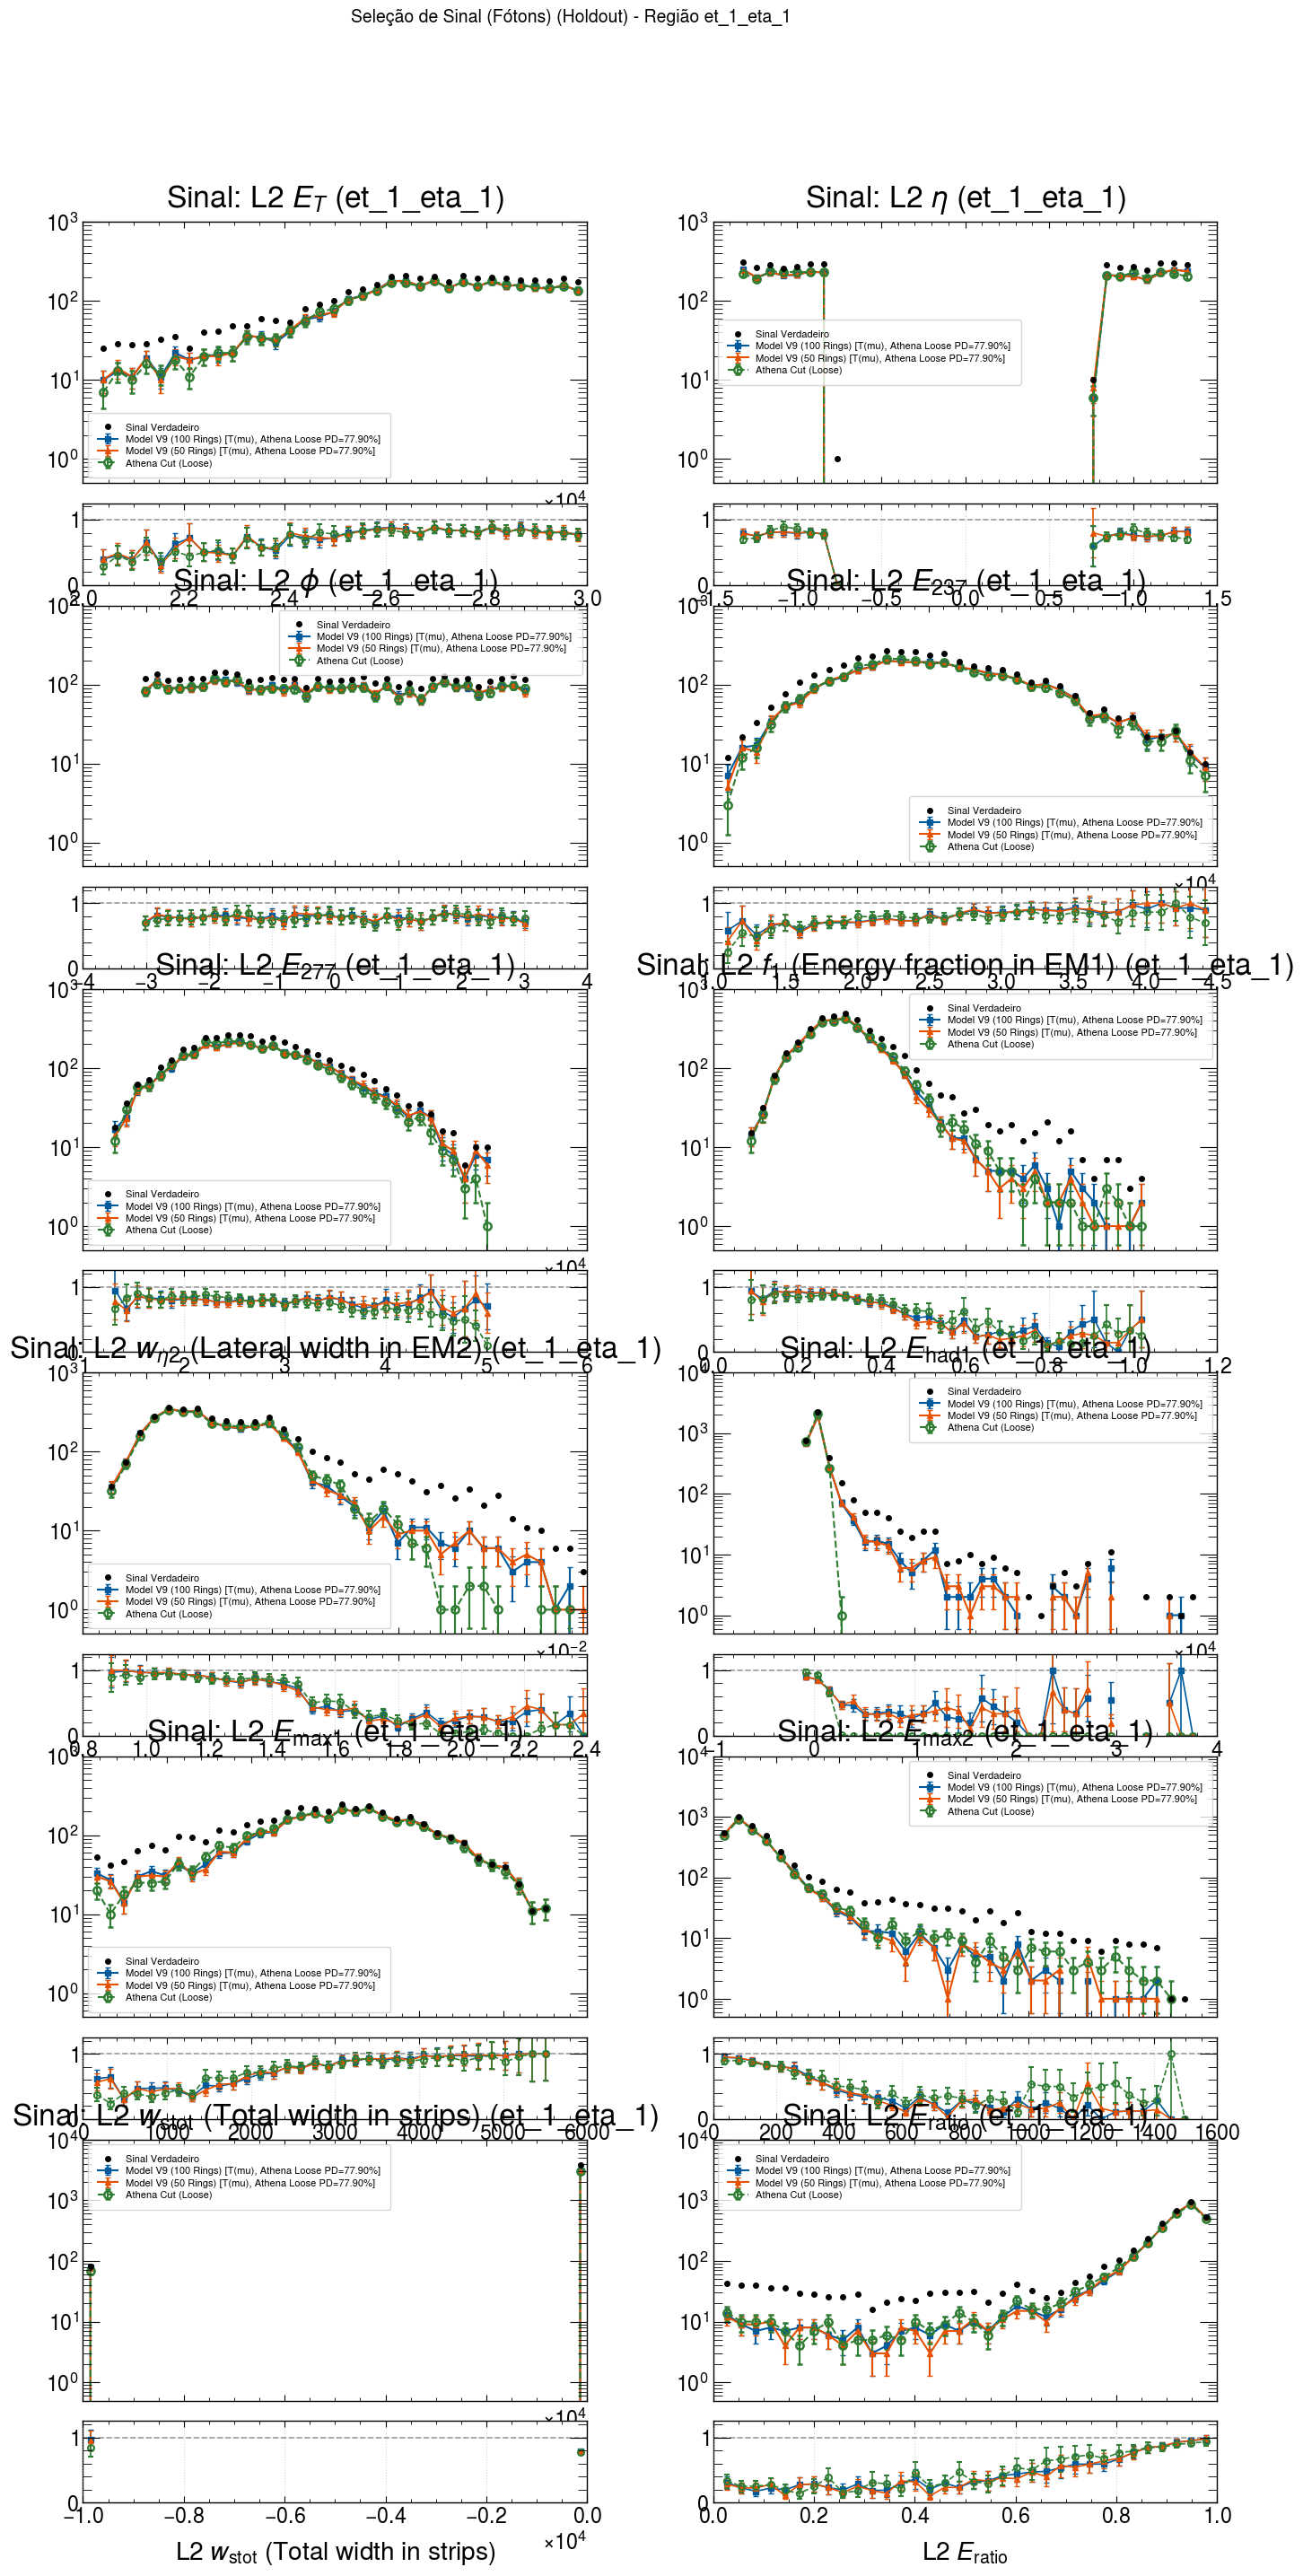

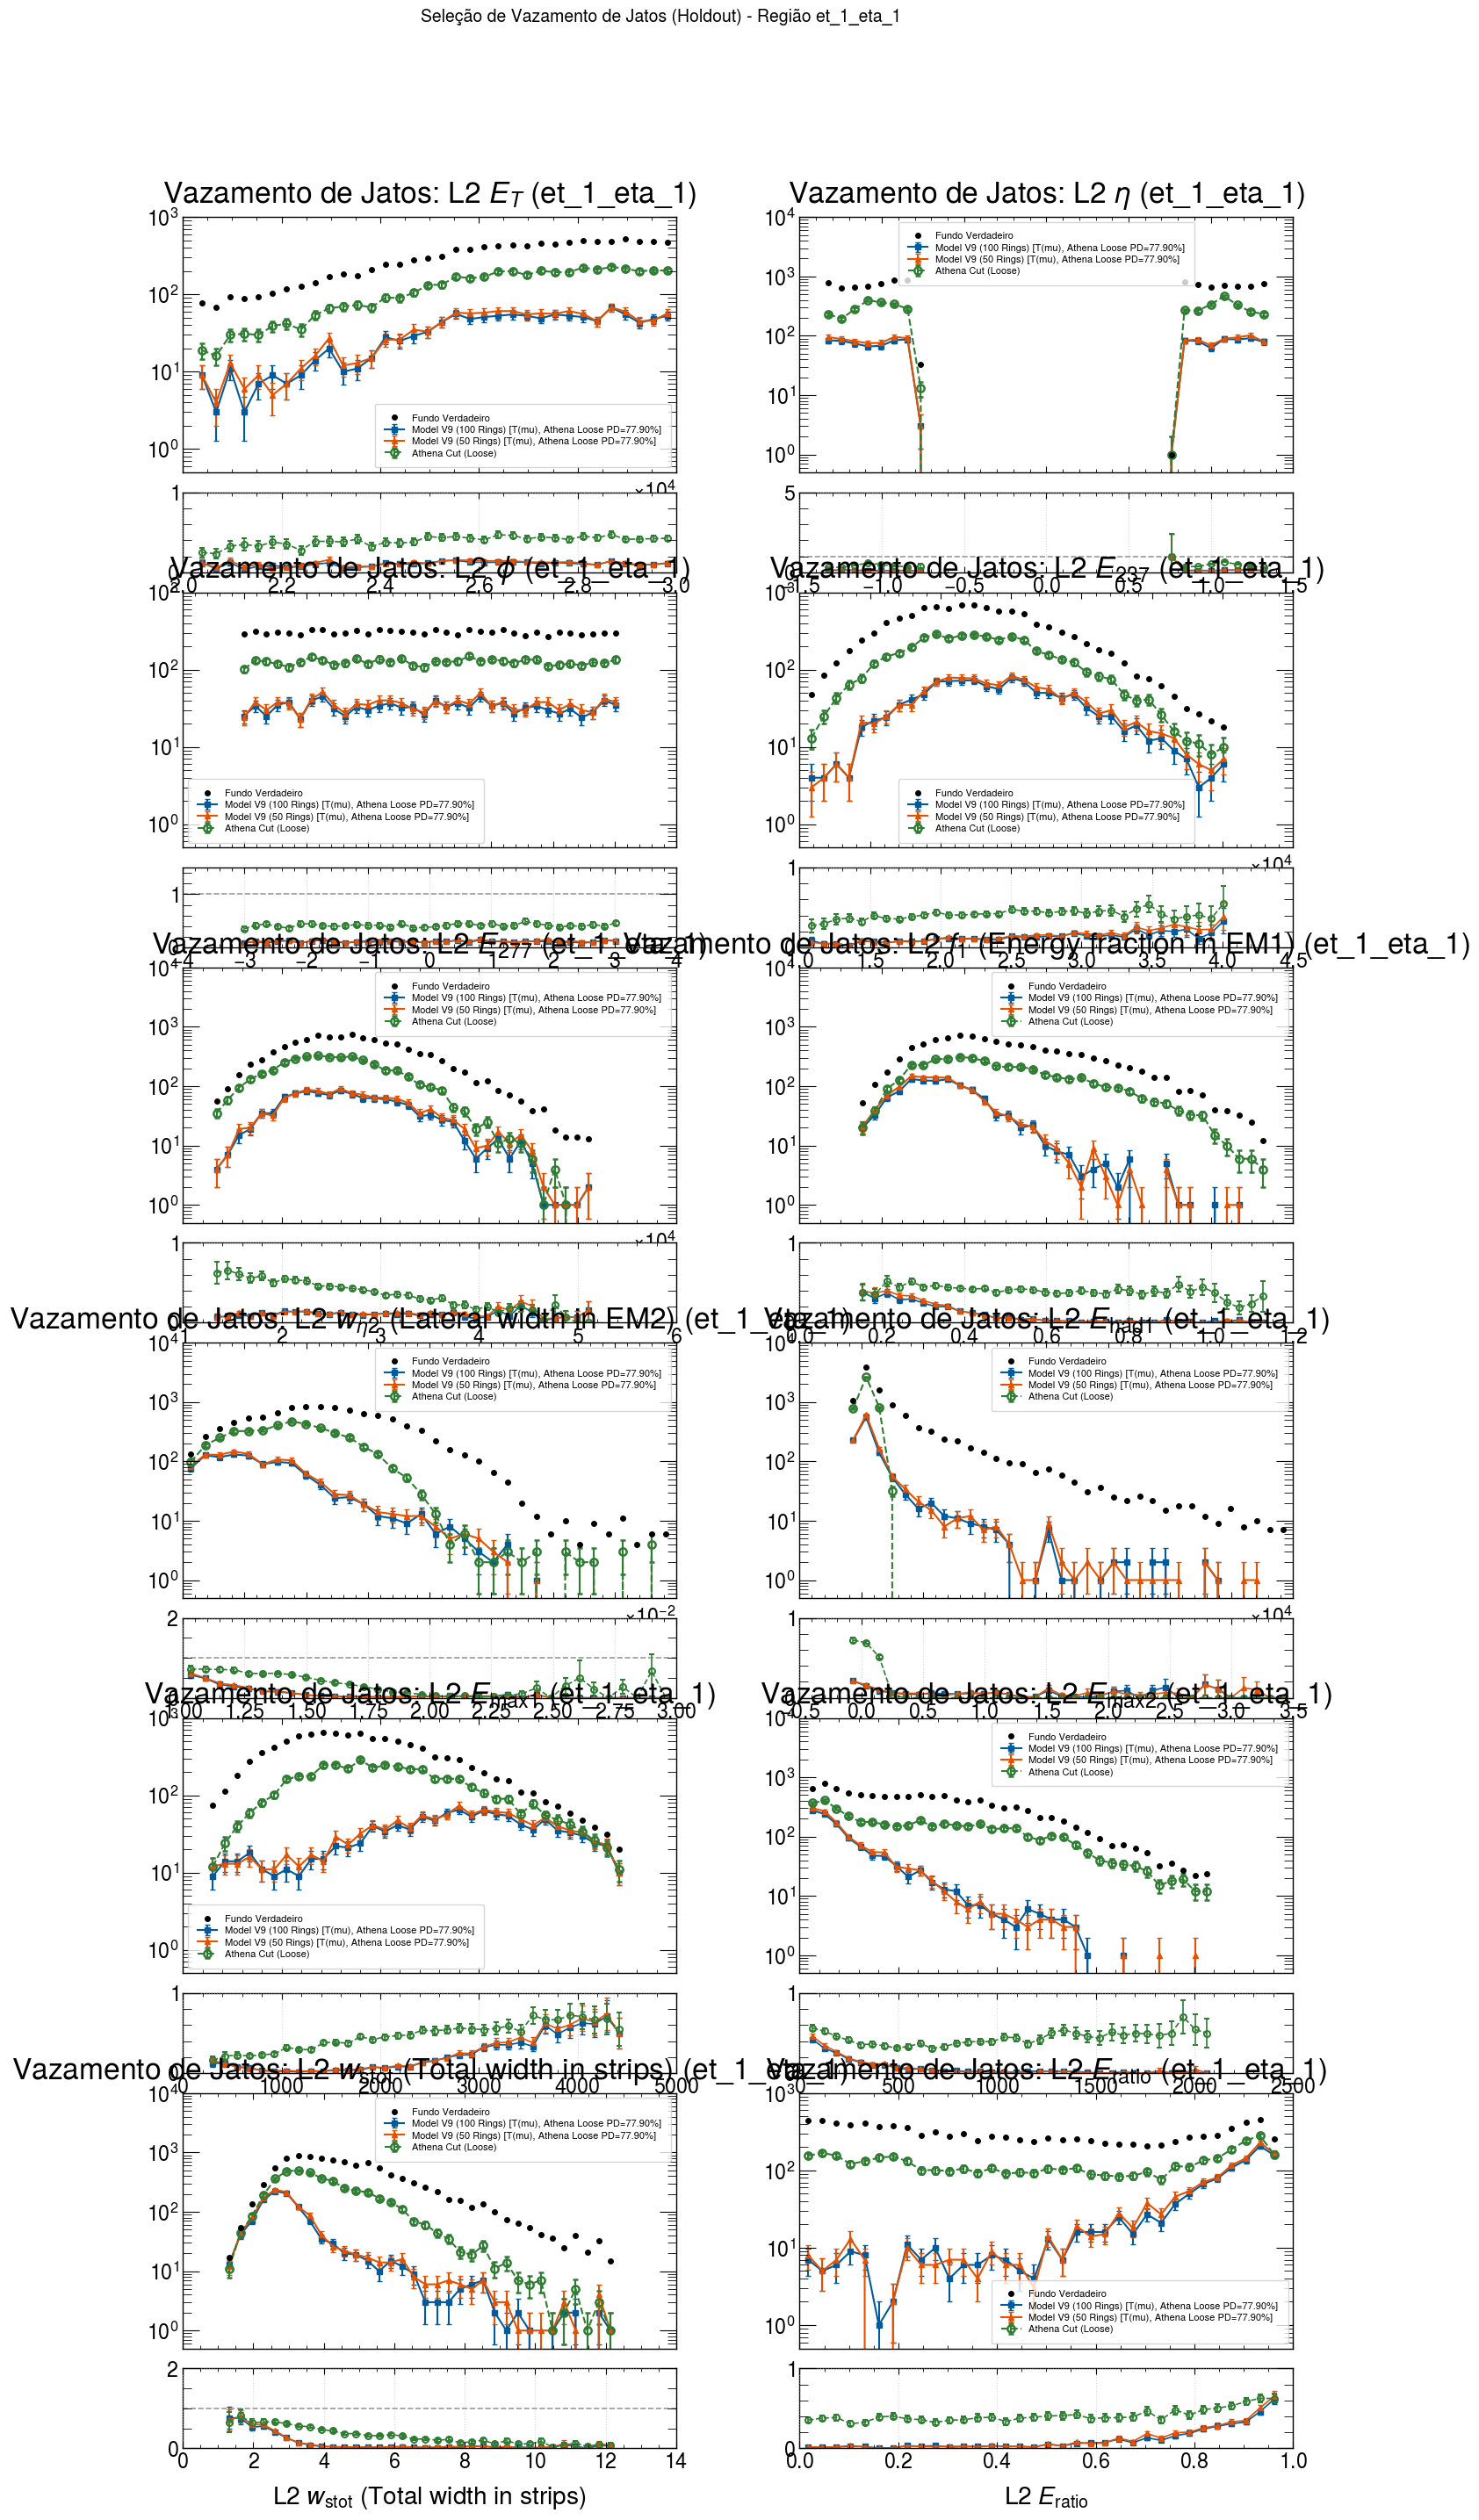

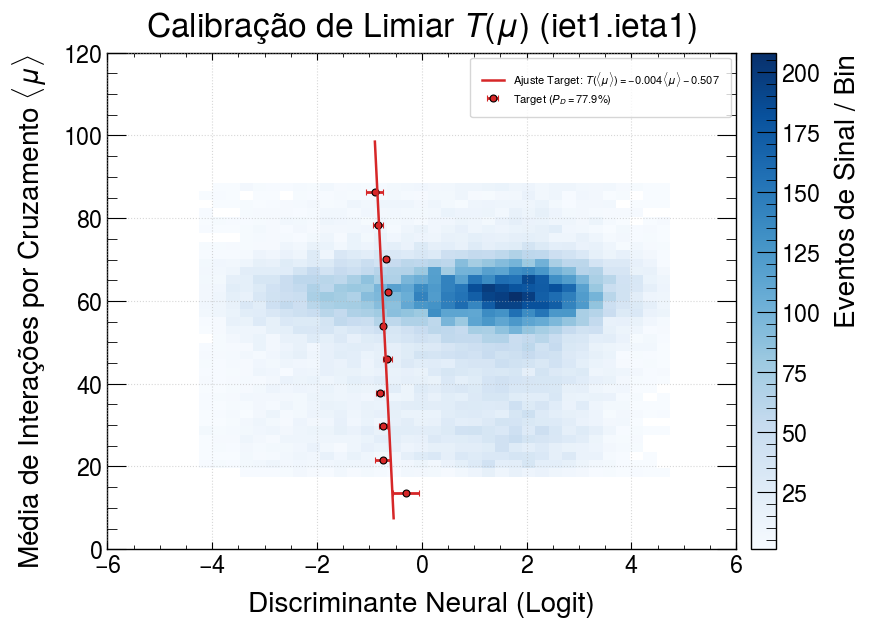

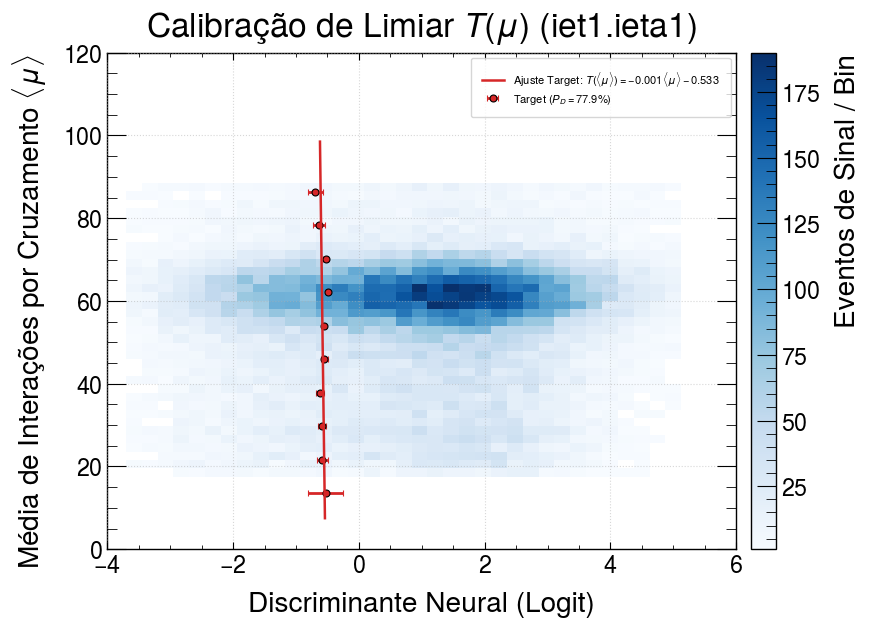

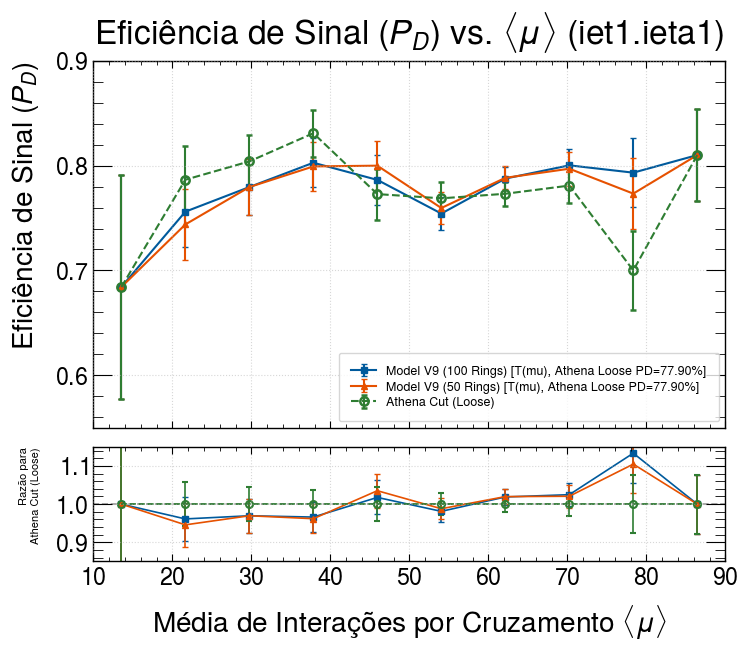

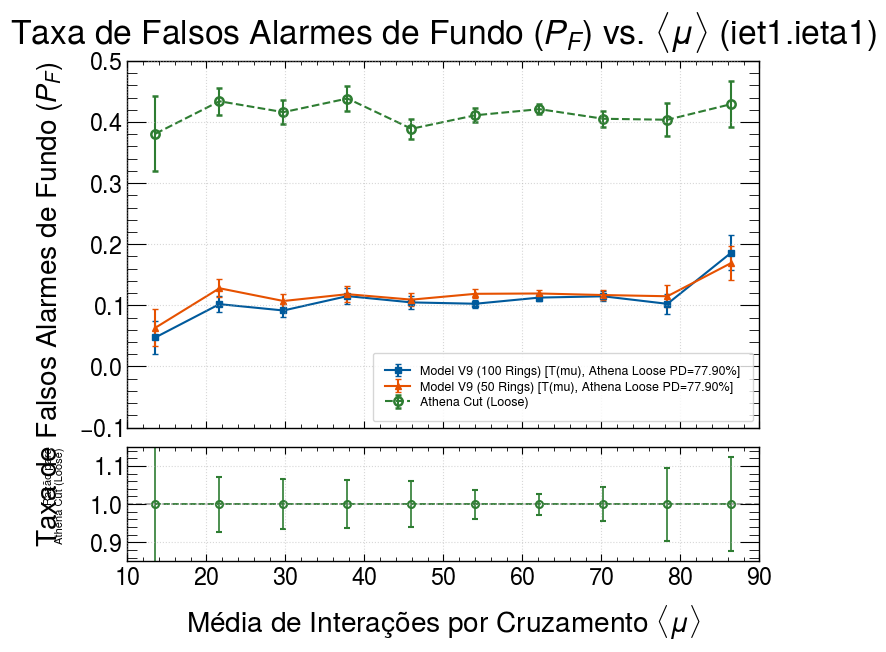

In [6]:
regions_to_run = (
    TARGET_REGIONS
    if TARGET_REGIONS is not None
    else SingleRegionComparisonRunner.discover_regions(MANIFEST_PATH)
)
show_inline = len(regions_to_run) == 1
print(f"Running {len(regions_to_run)} region(s): {regions_to_run}")

for iet, ieta in regions_to_run:
    print(f"\n=== Region et_{iet}_eta_{ieta} ===")
    runner = SingleRegionComparisonRunner(
        iet=iet,
        ieta=ieta,
        model1=MODEL_1,
        model2=MODEL_2,
        compare_same_model=COMPARE_SAME_MODEL,
        target_pd_mode=TARGET_PD_MODE,
        custom_target_pd=CUSTOM_TARGET_PD,
        working_point=WORKING_POINT,
        data_path=DATA_PATH,
        manifest_path=MANIFEST_PATH,
        language=LANGUAGE,
        plot_format=PLOT_FORMAT,
        log_y=LOG_Y,
    )
    OUTPUT_DIR: Path = runner.build_output_dir(OUTPUT_BASE_DIR, mode=COMPARISON_MODE)
    TABLES_DIR: Path = OUTPUT_DIR / "Tables"
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)

    payload = runner.prepare(mode=COMPARISON_MODE, features_to_plot=FEATURES_TO_PLOT)
    print(f"Output dir: {OUTPUT_DIR}")
    print(f"Comparing:  {payload.strategy1_name}  vs  {payload.strategy2_name} ({len(payload.test_labels):,} test events)")

    strategy_df, counts_df, saved_quad = runner.run_quadrant_analysis(payload, OUTPUT_DIR, TABLES_DIR)
    sig_js_df, fig_sig = runner.run_variable_analysis(payload, OUTPUT_DIR, TABLES_DIR, is_signal=True)
    bg_js_df, fig_bg = runner.run_variable_analysis(payload, OUTPUT_DIR, TABLES_DIR, is_signal=False)
    fit_df, pileup_figs = runner.run_pileup_analysis(payload, OUTPUT_DIR, TABLES_DIR)
    if show_inline and not fit_df.empty:
        display(fit_df)
    if show_inline:
        display(strategy_df)
        display(counts_df)
        display(sig_js_df)
        display(bg_js_df)
        plt.show()
    else:
        plt.close("all")
    gc.collect()